### Expoloring in GEE 

## Introduction

This notebook is designed to explore Landsat8 data for the guyana coastline and seek to understand the potential incorporation of NDVI, SI and digital elevation models into extent maps. The resources helped to assist in this notebook include: 
- [Youtube Tutorial](https://www.youtube.com/watch?v=amPaUC5QYOY&list=PLmk0fUBXB9t0AZioQipqHv5tuE3kpIdvI&index=9)
- [Google Earth Engine Docs](https://developers.google.com/earth-engine/datasets/catalog/LANDSAT_LC08_C02_T1_L2#colab-python)
- [Geemap Tutorial](https://courses.geemap.org/gee_intro/Image/image_colorbar/)
- [Gemini 3.5 Flash](https://gemini.google.com/) 

In [4]:
import ee

ee.Authenticate()
ee.Initialize(project='irp-zu')

### Retrieving Landsat8 and applying scaling factors/offsets after values have been atmospherically corrected

In [5]:
import geemap

coastline_coords = [[-59.755689785228235, 8.126814578766439],
          [-57.833082363353235, 5.607387745118143],
          [-57.146881951761834, 5.898364580242008],
          [-57.009580630573, 6.02949062794878],
          [-56.888703240824334, 6.15511611857417],
          [-56.493195428324334, 6.624592088692309],
          [-56.416291131449334, 7.785376639618971],
          [-58.45482139063248, 9.543371065466095],
          [-59.98741416406998, 8.545208575574712]]

aoi_polygon = ee.Geometry.Polygon([coastline_coords])
aoi_polygon

start_date = "2020-01-01"
end_date = "2020-12-31"

landsat = ee.ImageCollection("LANDSAT/LC08/C02/T1_L2").filterDate(start_date, end_date).filterBounds(aoi_polygon)

# Applies scaling factors.
# https://developers.google.com/earth-engine/datasets/catalog/LANDSAT_LC08_C02_T1_L2#colab-python
def apply_scale_factors(image):
  optical_bands = image.select('SR_B.').multiply(0.0000275).add(-0.2)
  thermal_bands = image.select('ST_B.*').multiply(0.00341802).add(149.0)
  return image.addBands(optical_bands, None, True).addBands(
      thermal_bands, None, True
  )


Visualizing a median composite image that masks most of the clouds and cloud shadow

In [6]:
dataset = landsat.map(apply_scale_factors)



# CRITICAL: Create a cloud-free median composite and clip to your AOI
# Help from GEMINI: https://gemini.google.com/share/fc15b73f73d2
guyana_coast_image = dataset.median().clip(aoi_polygon)



visualization = {
    'bands': ['SR_B4', 'SR_B3', 'SR_B2'],
    'min': 0.0,
    'max': 0.3,
}

m = geemap.Map()
m.center_object(aoi_polygon, 7)
m.add_layer(guyana_coast_image, visualization, 'True Color (432)')
m

Map(center=[7.625000281267503, -58.02523831094688], controls=(WidgetControl(options=['position', 'transparent_…

### Generating a NDVI time series to see how NDVI changes over the year and to assess how NDVI varies in seasonality

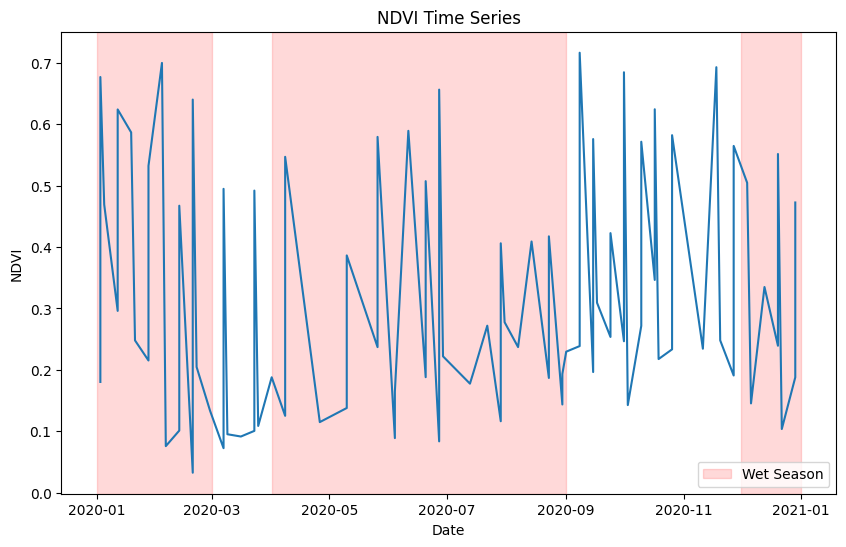

In [7]:
#Tutorial: https://www.youtube.com/watch?v=amPaUC5QYOY&list=PLmk0fUBXB9t0AZioQipqHv5tuE3kpIdvI&index=9

import matplotlib.pyplot as plt;
import datetime

def calculate_ndvi(image): 
    ndvi = image.normalizedDifference(['SR_B5', 'SR_B4']).rename('NDVI')
    return image.addBands(ndvi)

landsat_with_ndvi = dataset.map(calculate_ndvi)

"""
The reduce_region function takes an image of pixels, 
filters the image to the area of interest and then 
calculates all the ndvi values for each 30m pixel 
and then sums up the values and divides it by the 
total number of pixels in the area of interest to 
get a mean ndvi for that specific date
"""
def reduce_region(image):
    # clipping to the area of interest, setting the pixel scale (30m res for landsat), reduce the ndvi values from each pixel into a single mean value
    mean_ndvi = image.reduceRegion(reducer=ee.Reducer.mean(), geometry=aoi_polygon, scale=30, bestEffort=True).get('NDVI')
    # bestEffort helps to prevent crashing by looking at 60m/90m if needed) 
    date = ee.Date(image.get('system:time_start')).format('YYY-MM-dd')
    return ee.Feature(None , {'date': date, 'NDVI': mean_ndvi}) # sum ndvi of all pixels in aoi / total number of pixels 

ndvi_time_series = landsat_with_ndvi.map(reduce_region).sort('date') # sorts choronologically since its not the case from the reducer

ndvi_values = ndvi_time_series.aggregate_array('NDVI').getInfo()

dates = ndvi_time_series.aggregate_array('date').getInfo()

# print('unsorted', landsat_with_ndvi.map(reduce_region).aggregate_array('date').getInfo())
# print('sorted', dates)
dates = [datetime.datetime.strptime(date, '%Y-%m-%d') for date in dates]

wet_season = [['2020-04', '2020-09'], ['2020-01', '2020-03'], ['2020-12', '2021-01']]
# dry_season = [['03'], ['09', '11']]

plt.figure(figsize=(10,6))
plt.plot(dates, ndvi_values)
labeled=False
for szn in wet_season:
    lbl = 'Wet Season' if not labeled else None
    plt.axvspan(szn[0], szn[1], color="red", alpha=0.15, label=lbl)
    labeled=True
plt.xlabel('Date')
plt.ylabel('NDVI')
plt.title('NDVI Time Series')
plt.legend(loc='lower right')
plt.show()

In [8]:
Map = geemap.Map()

NDVI = landsat_with_ndvi.select('NDVI').mean().clip(aoi_polygon)
Map.addLayer(NDVI, {'min': 0, 'max': 1, 'palette': ['white', 'red']}, 'NDVI')
Map.centerObject(aoi_polygon, zoom=8)

Map

Map(center=[7.625000281267503, -58.02523831094688], controls=(WidgetControl(options=['position', 'transparent_…

### Generating a SI (Salinity Index) time series to see how SI changes over the year

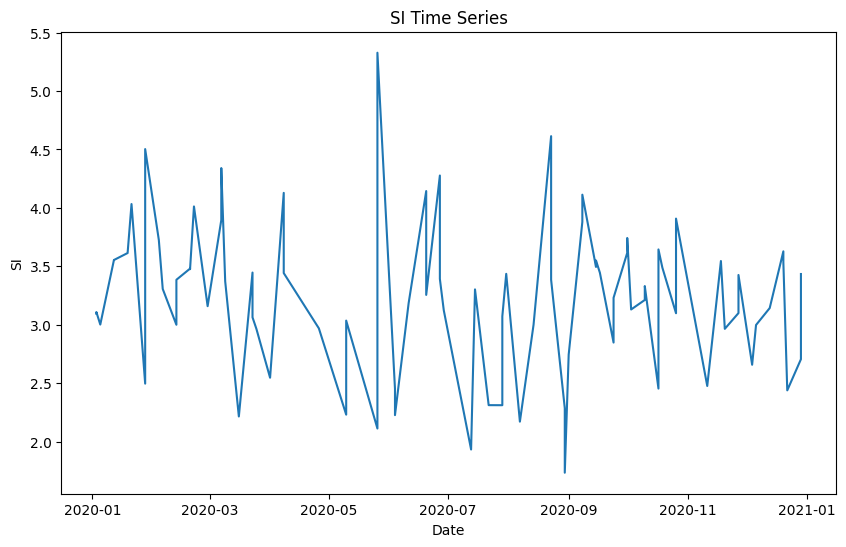

In [9]:
def calculate_si(image): 
    si = image.expression('(GREEN + RED) / BLUE', {
        'GREEN': image.select('SR_B3'),
        'RED': image.select('SR_B4'),
        'BLUE': image.select('SR_B2')
    }).rename('SI')
    return image.addBands(si)

landsat_with_si = dataset.map(calculate_si)

def reduce_region(image, index):
    # clipping to the area of interest, setting the pixel scale (30m res for landsat), reduce the index values from each pixel into a single mean value
    mean_index = image.reduceRegion(reducer=ee.Reducer.mean(), geometry=aoi_polygon, scale=30, bestEffort=True).get(index)
    # bestEffort helps to prevent crashing by looking at 60m/90m if needed) 
    date = ee.Date(image.get('system:time_start')).format('YYY-MM-dd')
    return ee.Feature(None , {'date': date, index: mean_index}) # sum index of all pixels in aoi / total number of pixels 

si_time_series = landsat_with_si.map(lambda x: reduce_region(x, "SI")).sort('date') # sorts choronologically since its not the case from the reducer

si_values = si_time_series.aggregate_array('SI').getInfo()

dates = si_time_series.aggregate_array('date').getInfo()
dates = [datetime.datetime.strptime(date, '%Y-%m-%d') for date in dates]

plt.figure(figsize=(10,6))
plt.plot(dates, si_values)
plt.xlabel('Date')
plt.ylabel('SI')
plt.title('SI Time Series')
plt.show()


In [10]:
Map = geemap.Map()

SI = landsat_with_si.select('SI').mean().clip(aoi_polygon)
Map.addLayer(SI, {'min': 0, 'max': 5.5, 'palette': ['white', 'red']}, 'SI')
Map.centerObject(aoi_polygon, zoom=10)

Map

Map(center=[7.625000281267503, -58.02523831094688], controls=(WidgetControl(options=['position', 'transparent_…

A bit unclear to see the relation with salinity since the value quite red at the sea. It's also quite noisey with speckle, uncharacteristic of a Salinity index. Could indicate a moisture or turbidity signal, perhaps reflecting off mudflats and bare surfaces 

In [11]:
# srtm = ee.Image("USGS/SRTMGL1_003") # loading elevation dataset 
merit_dem = ee.Image("MERIT/DEM/v1_0_3").select('dem') # For true more accurate DEM that filters out canopy heights
guyana = ee.FeatureCollection("USDOS/LSIB_SIMPLE/2017").filter(ee.Filter.eq('country_na', 'Guyana'))
guyana_geom = guyana.geometry()

# elevation = srtm.clip(guyana_geom)
elevation = merit_dem.clip(guyana_geom)

elevation_vis = {
    'min': 0,     # 0 meters (Sea level)
    'max': 50,    # 50 meters (Adjust this higher if you go inland into the mountains)
    'palette': ['darkgreen', 'green', 'yellow', 'orange', 'brown']
}

hillshade = ee.Terrain.hillshade(elevation)
hillshade

Showing the MERIT based elevation map which masks out canopy heights to get a more accurate ground elevation. Along the coast shows the area to be flat and homogenous, ideal for mangrove detection.  

In [14]:
map_elev = geemap.Map()
map_elev.center_object(guyana_geom, zoom=7)
map_elev.add_layer(elevation, elevation_vis, 'Elevation (meters above sea level)')
map_elev.add_layer(hillshade, {'min': 150, 'max': 255}, "Terrain Hillshade", opacity=0.2)

map_elev.add_layer(guyana_coast_image, visualization, "Satellite Over Terrain", opacity=0.3)
map_elev.add_colorbar(elevation_vis['palette'], 
                  vmin=elevation_vis['min'], 
                  vmax=elevation_vis['max'], 
                  layer_name="Elevation (m)",
                  position="bottomright")
map_elev

# shows a relatively flat coastline (gemini helped here: https://gemini.google.com/app/3d66a700a326f3f9) and 
# https://courses.geemap.org/gee_intro/Image/image_colorbar/

Map(center=[4.782974139864346, -58.97349900698443], controls=(WidgetControl(options=['position', 'transparent_…

Looking at the results from MERIT, it appears that a DEM is not that helpful in discriminating between the classes of mangroves and non-mangroves. While elevation is usually a clear demarkation metric, in this case, the coast is relatively homogenous falling between 0-10m above sea level. Are better mask would be the distance from the coast but that seems to be covered by my area of interest selection. 

### Testing if MNDWI can act as a mask for open water

In [16]:
def calculate_mndwi(image): 
    mndwi = image.normalizedDifference(['SR_B6', 'SR_B3']).rename('MNDWI')
    return image.addBands(mndwi)

landsat_with_mndwi = dataset.map(calculate_mndwi)
landsat_with_mndwi

Map = geemap.Map()

MNDWI = landsat_with_mndwi.select('MNDWI').mean().clip(aoi_polygon)
Map.addLayer(MNDWI, {'min': 0, 'max': 1, 'palette': ['white', 'red']}, 'MNDWI')
Map.centerObject(aoi_polygon, zoom=7)

Map

Map(center=[7.625000281267503, -58.02523831094688], controls=(WidgetControl(options=['position', 'transparent_…

Not so conclusive. 